<a href="https://colab.research.google.com/github/samiyasiddiq/Fire-Force/blob/main/Samiya_Siddiqua_23-52240-2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Libraries import
import torch, torch.nn as nn, torch.optim as optim
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt, numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


100%|██████████| 170M/170M [22:28<00:00, 126kB/s]


Train: 50000 Test: 10000


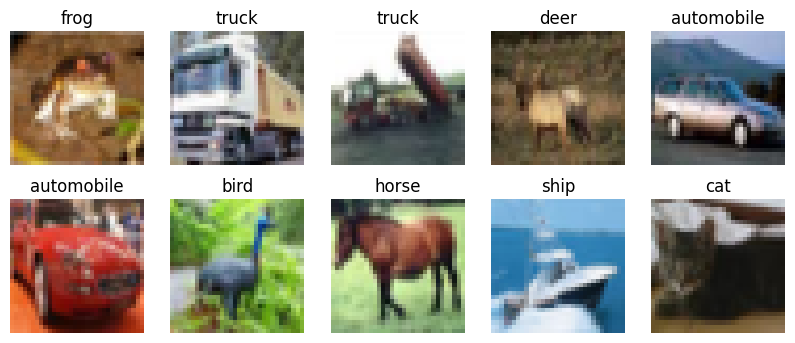

In [ ]:

classes = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

train_full = torchvision.datasets.CIFAR10('./data', train=True, download=True)
test_raw   = torchvision.datasets.CIFAR10('./data', train=False, download=True)
print("Train:", len(train_full), "Test:", len(test_raw))


fig, ax = plt.subplots(2, 5, figsize=(10, 4))
for i, a in enumerate(ax.flat):
    img, lbl = train_full[i]
    a.imshow(img); a.set_title(classes[lbl]); a.axis('off')
plt.show()

In [ ]:

norm = T.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))

train_tf = T.Compose([T.RandomHorizontalFlip(), T.RandomCrop(32, padding=4), T.ToTensor(), norm])
eval_tf  = T.Compose([T.ToTensor(), norm])

train_ds = torchvision.datasets.CIFAR10('./data', train=True, transform=train_tf)
val_base = torchvision.datasets.CIFAR10('./data', train=True, transform=eval_tf)
test_ds  = torchvision.datasets.CIFAR10('./data', train=False, transform=eval_tf)


g = torch.Generator().manual_seed(42)
idx = torch.randperm(50000, generator=g).tolist()
train_set = torch.utils.data.Subset(train_ds, idx[:45000])
val_set   = torch.utils.data.Subset(val_base, idx[45000:])

BATCH = 128
train_loader = DataLoader(train_set, BATCH, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_set, BATCH, num_workers=2)
test_loader  = DataLoader(test_ds, BATCH, num_workers=2)
print(len(train_set), len(val_set), len(test_ds))

45000 5000 10000


In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o):  # Conv -> BatchNorm -> ReLU -> Conv -> ReLU -> Pool
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                nn.Conv2d(o, o, 3, padding=1), nn.ReLU(),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3,32), block(32,64), block(64,128))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.5),
            nn.Linear(128*4*4, 256), nn.ReLU(),
            nn.Linear(256, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

model = CNN().to(device)
!pip install torchinfo -q
from torchinfo import summary
summary(model, input_size=(1,3,32,32))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [1, 10]                   --
├─Sequential: 1-1                        [1, 128, 4, 4]            --
│    └─Sequential: 2-1                   [1, 32, 16, 16]           --
│    │    └─Conv2d: 3-1                  [1, 32, 32, 32]           896
│    │    └─BatchNorm2d: 3-2             [1, 32, 32, 32]           64
│    │    └─ReLU: 3-3                    [1, 32, 32, 32]           --
│    │    └─Conv2d: 3-4                  [1, 32, 32, 32]           9,248
│    │    └─ReLU: 3-5                    [1, 32, 32, 32]           --
│    │    └─MaxPool2d: 3-6               [1, 32, 16, 16]           --
│    └─Sequential: 2-2                   [1, 64, 8, 8]             --
│    │    └─Conv2d: 3-7                  [1, 64, 16, 16]           18,496
│    │    └─BatchNorm2d: 3-8             [1, 64, 16, 16]           128
│    │    └─ReLU: 3-9                    [1, 64, 16, 16]           --
│    │

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
EPOCHS = 15
hist = {'tl':[], 'vl':[], 'ta':[], 'va':[]}

def run(loader, train):
    model.train(train)
    loss_sum, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            loss_sum += loss.item()*len(y)
            correct += (out.argmax(1)==y).sum().item(); n += len(y)
    return loss_sum/n, correct/n

for e in range(EPOCHS):
    tl, ta = run(train_loader, True)
    vl, va = run(val_loader, False)
    for k, v in zip(['tl','vl','ta','va'], [tl,vl,ta,va]): hist[k].append(v)
    print(f"Epoch {e+1}/{EPOCHS} | Train Loss {tl:.3f} Acc {ta:.3f} | Val Loss {vl:.3f} Acc {va:.3f}")

Epoch 1/15 | Train Loss 1.504 Acc 0.438 | Val Loss 1.197 Acc 0.569
Epoch 2/15 | Train Loss 1.103 Acc 0.601 | Val Loss 0.975 Acc 0.652
Epoch 3/15 | Train Loss 0.940 Acc 0.666 | Val Loss 0.876 Acc 0.695
Epoch 4/15 | Train Loss 0.844 Acc 0.702 | Val Loss 0.779 Acc 0.724
Epoch 5/15 | Train Loss 0.767 Acc 0.729 | Val Loss 0.824 Acc 0.721
Epoch 6/15 | Train Loss 0.717 Acc 0.748 | Val Loss 0.634 Acc 0.780
Epoch 7/15 | Train Loss 0.672 Acc 0.766 | Val Loss 0.629 Acc 0.782
Epoch 8/15 | Train Loss 0.642 Acc 0.776 | Val Loss 0.598 Acc 0.793
Epoch 9/15 | Train Loss 0.610 Acc 0.789 | Val Loss 0.622 Acc 0.782
Epoch 10/15 | Train Loss 0.592 Acc 0.793 | Val Loss 0.543 Acc 0.813
Epoch 11/15 | Train Loss 0.566 Acc 0.804 | Val Loss 0.534 Acc 0.818
Epoch 12/15 | Train Loss 0.541 Acc 0.813 | Val Loss 0.507 Acc 0.828
Epoch 13/15 | Train Loss 0.526 Acc 0.818 | Val Loss 0.495 Acc 0.827
Epoch 14/15 | Train Loss 0.508 Acc 0.824 | Val Loss 0.476 Acc 0.835
Epoch 15/15 | Train Loss 0.494 Acc 0.831 | Val Loss 0.521

Test Accuracy: 0.8243
              precision    recall  f1-score   support

    airplane       0.91      0.74      0.82      1000
  automobile       0.96      0.88      0.92      1000
        bird       0.76      0.78      0.77      1000
         cat       0.68      0.74      0.71      1000
        deer       0.73      0.89      0.80      1000
         dog       0.85      0.69      0.76      1000
        frog       0.82      0.90      0.86      1000
       horse       0.94      0.77      0.84      1000
        ship       0.80      0.96      0.87      1000
       truck       0.90      0.90      0.90      1000

    accuracy                           0.82     10000
   macro avg       0.83      0.82      0.82     10000
weighted avg       0.83      0.82      0.82     10000



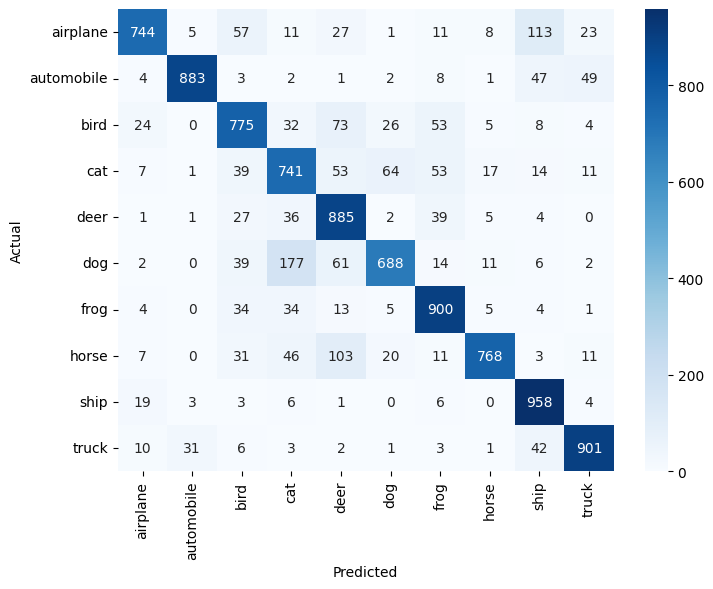

In [ ]:
model.eval(); preds, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        preds += model(x.to(device)).argmax(1).cpu().tolist(); labels += y.tolist()

print("Test Accuracy:", np.mean(np.array(preds)==np.array(labels)))
print(classification_report(labels, preds, target_names=classes))
plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(labels, preds), annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

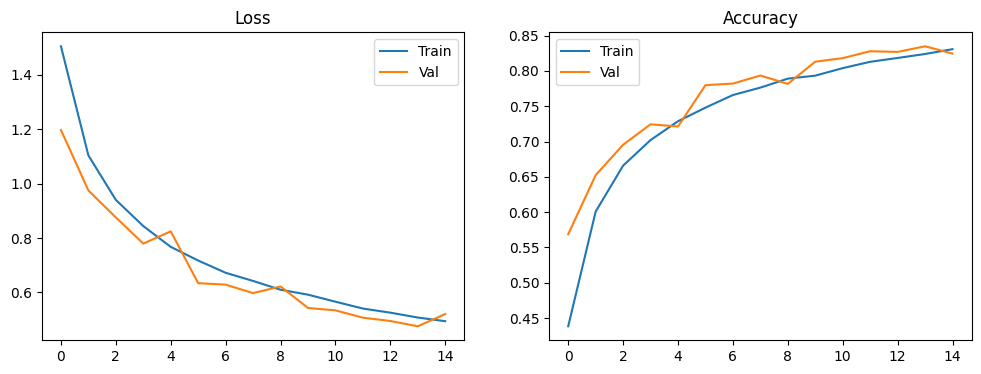

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(hist['tl'], label='Train'); ax[0].plot(hist['vl'], label='Val'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(hist['ta'], label='Train'); ax[1].plot(hist['va'], label='Val'); ax[1].set_title('Accuracy'); ax[1].legend()
plt.show()

In [ ]:
torch.save(model.state_dict(), 'cnn_cifar10.pth')
import os; print("Size (MB):", os.path.getsize('cnn_cifar10.pth')/1e6)

Size (MB): 3.271386


# CNN Classification on CIFAR-10
**Name:** Samiya Siddiqua | **ID:** 23-52240-2
**Course:** CVPR | **Framework:** PyTorch

## Dataset Description
- **Name:** CIFAR-10
- **Source:** https://www.cs.toronto.edu/~kriz/cifar.html (loaded via torchvision)
- **Size:** 60,000 color images, 32x32 pixels, 3 channels (RGB)
- **Classes (10):** airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck
- **Split:** 45,000 train, 5,000 validation, 10,000 test
- **Why this dataset:** It is open access, multi-class, balanced (equal images per class) and small, so it trains quickly on a free GPU.

## Preprocessing & Augmentation
- **Normalization (mean 0.5, std 0.5):
** scales pixels to [-1, 1] and makes training stable.
- **RandomHorizontalFlip and RandomCrop(padding=4):** applied only on training data to reduce overfitting.
- **Split:** 45,000 / 5,000 using a fixed seed (42) for reproducibility.
- **Batch size 128:** a good balance between speed and stable gradients.

## CNN Architecture
The custom CNN has 3 blocks, each with: Conv -> BatchNorm -> ReLU -> Conv -> ReLU -> MaxPool.
Filters increase 32 -> 64 -> 128, then a classifier: Flatten -> Dropout(0.5) -> Linear(2048,256) -> ReLU -> Linear(256,10).

**Justification:**
- Convolution layers learn local features (edges, then shapes, then objects).
- Increasing filters capture more complex patterns in deeper layers.
- MaxPool reduces size and computation.
- BatchNorm makes training faster and more stable.
- Dropout (0.5) reduces overfitting in the fully connected layer.
- ReLU adds non-linearity.

## Training Setup
| Hyperparameter | Value | Reason |
|---|---|---|
| Loss | CrossEntropyLoss | Standard for multi-class classification |
| Optimizer | Adam | Adaptive learning rate, converges fast |
| Learning rate | 0.001 | Common default for Adam |
| Epochs | 15 | Enough to converge within Colab time limits |
| Batch size | 128 | Balance of speed and stability |

## Analysis & Discussion
- The model reached **82.43% test accuracy**, close to the final validation accuracy (82.4%), so it generalizes well.
- Train and validation curves stay close together, so there is **no serious overfitting**. Augmentation, BatchNorm and Dropout helped.
- Loss kept decreasing and accuracy kept increasing until epoch 15, so more epochs could improve results.
- **Best classes:** automobile (F1 0.92), truck (0.90), ship (0.87), frog (0.86).
- **Weakest classes:** cat (F1 0.71), dog (0.76) and bird (0.77). The confusion matrix shows 177 dogs were predicted as cats, because they look similar at 32x32 size.
- Airplane had low recall (0.74), as 113 airplanes were confused with ships (similar blue background).

## Conclusion
A custom CNN trained from scratch on CIFAR-10 achieved 82.43% test accuracy with no major overfitting. The trained weights are saved as `cnn_cifar10.pth` (3.27 MB).

## Future Work
- Train for more epochs with a learning rate scheduler.
- Try stronger augmentation (rotation, color jitter, Cutout).
- Use a deeper model (e.g. ResNet-style skip connections) or transfer learning.
- Try other optimizers like SGD with momentum.